# A daily-summary CSV: trends and a weekly view

Many wearable exports boil down to one row per day. This notebook shows the pandas steps that work on any of them: parse the date column, add 7-day rolling means, compare two metrics, and resample by week.

**The input here is synthetic** (`daily-summary-synthetic.csv` from [https://aifitnessapi.com/own-your-data](https://aifitnessapi.com/own-your-data#notebooks)), generated from a fixed seed. Its column names are **ours, not any vendor's**: no vendor's CSV layout was verified for this notebook. To use your own export, set `CSV` and map your columns in `COLUMNS`. Lines starting with `#` are comments and are skipped.

In [1]:
import os, urllib.request

def local_or_download(path, url):
    """Use the file next to this notebook if it is there (a clone of the repo),
    otherwise download the synthetic sample once (Colab)."""
    if os.path.exists(path):
        return path
    name = os.path.basename(path)
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)
    return name

CSV = local_or_download("data/daily-summary-synthetic.csv",
                        "https://aifitnessapi.com/notebooks/data/daily-summary-synthetic.csv")

# Map your file's column names to the names used below.
COLUMNS = {"date": "date", "steps": "steps", "sleep_hours": "sleep_hours",
           "resting_hr_bpm": "resting_hr_bpm", "weight_kg": "weight_kg"}

In [2]:
import pandas as pd
d = pd.read_csv(CSV, comment="#").rename(columns={v: k for k, v in COLUMNS.items()})
d["date"] = pd.to_datetime(d["date"])
d = d.set_index("date").sort_index()
d.head()

,steps,distance_km,active_kcal,resting_hr_bpm,avg_hr_bpm,sleep_hours,weight_kg
date,,,,,,,
2026-06-01,6050,4.54,319,58,75,5.70,72.4
2026-06-02,8397,6.30,354,62,77,6.60,NaN
2026-06-03,7548,5.66,449,52,77,6.28,NaN
2026-06-04,7349,5.51,411,60,76,4.77,72.2
2026-06-05,7445,5.58,349,55,79,5.70,NaN


## Rolling means

Day-to-day numbers are noisy; a 7-day rolling mean is the usual first look. `min_periods` keeps the first days from being blank.

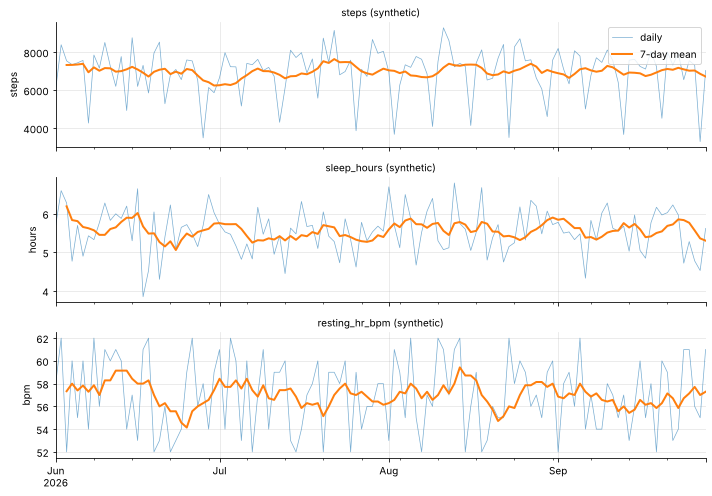

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 72})

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, col, unit in zip(axes, ["steps", "sleep_hours", "resting_hr_bpm"], ["steps", "hours", "bpm"]):
    d[col].plot(ax=ax, lw=0.7, alpha=0.6, label="daily")
    d[col].rolling(7, min_periods=3).mean().plot(ax=ax, lw=2, label="7-day mean")
    ax.set_ylabel(unit); ax.set_title(col + " (synthetic)", fontsize=10)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("")
plt.tight_layout(); plt.show()

## Weight: sparse readings

Weight is logged every few days, so most rows are empty. Plot the readings themselves, and interpolate only for a trend line.

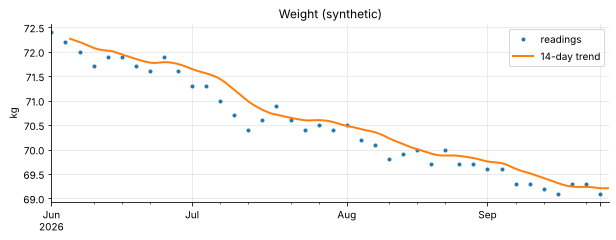

40 readings over 120 days


In [4]:
w = d["weight_kg"].dropna()
ax = w.plot(style="o", ms=3, label="readings", title="Weight (synthetic)")
d["weight_kg"].interpolate(limit_area="inside").rolling(14, min_periods=5).mean().plot(ax=ax, lw=2, label="14-day trend")
ax.set_ylabel("kg"); ax.set_xlabel(""); ax.legend()
plt.show()
print(f"{len(w)} readings over {len(d)} days")

## Does sleep move with resting heart rate?

A correlation and a scatter are the honest first step. On this synthetic file the two columns were generated independently, so expect a value near zero: the point is the method, not the result.

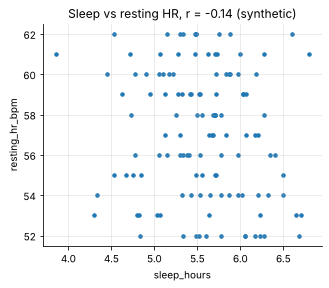

In [5]:
r = d["sleep_hours"].corr(d["resting_hr_bpm"])
ax = d.plot.scatter(x="sleep_hours", y="resting_hr_bpm", s=12, figsize=(5, 4),
                    title=f"Sleep vs resting HR, r = {r:.2f} (synthetic)")
plt.show()

## Weekly view

`resample("W-MON", label="left", closed="left")` gives Monday-starting weeks. Steps are summed and averaged; sleep and heart rate are averaged.

In [6]:
weekly = d.resample("W-MON", label="left", closed="left").agg(
    {"steps": ["sum", "mean"], "sleep_hours": "mean", "resting_hr_bpm": "mean"}).round(1)
weekly.columns = ["steps_total", "steps_per_day", "sleep_hours", "resting_hr"]
weekly

,steps_total,steps_per_day,sleep_hours,resting_hr
date,,,,
2026-06-01,48636,6948.0,5.6,57.3
2026-06-08,49726,7103.7,5.9,59.1
2026-06-15,49932,7133.1,5.2,56.3
2026-06-22,45639,6519.9,5.6,56.3
2026-06-29,46315,6616.4,5.6,57.6
2026-07-06,47688,6812.6,5.4,57.4
2026-07-13,50089,7155.6,5.5,56.3
2026-07-20,50629,7232.7,5.3,57.0
2026-07-27,49161,7023.0,5.7,56.6
